# RQ4: Extreme Temperature Deviations vs. Audio Features

**Research Question:** To what extent do extreme temperature deviations (very hot or very cold days) impact the average Danceability and Tempo of top-streamed songs?

---

## 1. Method

### 1.1 Temperature Deviation Calculation

The daily temperatures were also compared against the monthly climatological mean of that particular month in the calendar. A temperature of 5°C above the average January temperature is recorded as +5°C. Seasonal effects are taken out of the analysis in this way, leaving the impact of any abnormal weather for that season.

### 1.2 Extreme Classification (Percentile-based)

Using the **5th and 95th percentiles** of the deviation distribution, days were classified into three groups:

| Group | Definition |
|---|---|
| **Cold extreme** | deviation ≤ 5th percentile (unusually cold for that time of year) |
| **Hot extreme** | deviation ≥ 95th percentile (unusually hot for that time of year) |
| **Normal** | all other days |

### 1.3 Two Complementary Analytical Approaches

- **Kruskal-Wallis with Dunn's test** tests for differences in median values of the audio features between the three extreme groups. Tests if the extreme groups differ from the normal group categorically.
- **Regression of Deviation Magnitude (OLS)**  the regression of each audio feature on the absolute temperature deviation (i.e., `|temperature_deviation|`). Significance in the slope means that the magnitude of the deviation, rather than the sign, explains the listening behavior. A positive slope signifies an U-shape relationship; while a negative slope signifies an inverted-U relationship.

In [25]:
# Load result JSONs produced by the Snakemakee workflow
import json
import os
import pandas as pd
from IPython.display import Image

RESULTS_DIR = "../results/workflow_4"
FEATURES = ["tempo", "danceability", "valence", "energy", "acousticness"]

kruskal_results = {}
regression_results = {}

for feature in FEATURES:
    kruskal_path = os.path.join(RESULTS_DIR, f"kruskal_extremes_{feature}.json")
    regression_path = os.path.join(RESULTS_DIR, f"abs_dev_regression_{feature}.json")
    if os.path.exists(kruskal_path):
        with open(kruskal_path) as f:
            kruskal_results[feature] = json.load(f)
    if os.path.exists(regression_path):
        with open(regression_path) as f:
            regression_results[feature] = json.load(f)

print("Loaded Kruskal results for:", list(kruskal_results.keys()))
print("Loaded regression results for:", list(regression_results.keys()))

Loaded Kruskal results for: ['tempo', 'danceability', 'valence', 'energy', 'acousticness']
Loaded regression results for: ['tempo', 'danceability', 'valence', 'energy', 'acousticness']


In [26]:
# Summary table: Kruskal-Wallis results across all features
rows = []
for feature, r in kruskal_results.items():
    rows.append({
        "Feature": feature,
        "H statistic": r["h_statistic"],
        "p-value": r["p_value"],
        "Significant": r["significant_at_0.05"],
        "ε²": r["effect_size"]["epsilon_squared"],
        "Effect label": r["effect_size"]["label"],
    })

pd.DataFrame(rows)

,Feature,H statistic,p-value,Significant,ε²,Effect label
0,tempo,17.2057,0.000184,True,0.0094,negligible
1,danceability,10.8952,0.004307,True,0.0060,negligible
2,valence,20.2344,0.000040,True,0.0111,small
3,energy,8.4948,0.014301,True,0.0047,negligible
4,acousticness,1.0094,0.603686,False,0.0006,negligible


In [27]:
# Summary table: Magnitude regression results across all features
rows = []
for feature, r in regression_results.items():
    rows.append({
        "Feature": feature,
        "Slope": r["slope"],
        "p-value (slope)": r["slope_p_value"],
        "R²": r["r_squared"],
        "Effect label": r["effect_label"],
        "Significant": r["significant_at_0.05"],
    })

pd.DataFrame(rows)

,Feature,Slope,p-value (slope),R²,Effect label,Significant
0,tempo,-0.2665,0.000000,0.0005,negligible,True
1,danceability,-0.0001,0.687041,0.0000,negligible,False
2,valence,-0.0013,0.001023,0.0001,negligible,True
3,energy,0.0003,0.360712,0.0000,negligible,False
4,acousticness,0.0001,0.765388,0.0000,negligible,False


In [28]:
# Group summary: n, median, Q1, Q3 per group per feature
rows = []
for feature, r in kruskal_results.items():
    for group, stats in r["group_summary"].items():
        rows.append({
            "Feature": feature, "Group": group,
            "n": stats["n"], "Median": stats["median"],
            "Q1": stats["q1"], "Q3": stats["q3"],
        })
pd.DataFrame(rows).pivot_table(
    index=["Feature", "Group"], values=["n", "Median", "Q1", "Q3"]
).round(4)

Median        Q1        Q3       n
Feature      Group                                             
acousticness Cold extreme    0.2005    0.1819    0.2217    89.0
             Hot extreme     0.2009    0.1795    0.2181    97.0
             Normal          0.1985    0.1743    0.2195  1640.0
danceability Cold extreme    0.6754    0.6688    0.6864    89.0
             Hot extreme     0.6851    0.6715    0.6953    97.0
             Normal          0.6845    0.6709    0.6962  1640.0
energy       Cold extreme    0.6776    0.6625    0.6908    89.0
             Hot extreme     0.6814    0.6653    0.6963    97.0
             Normal          0.6731    0.6544    0.6886  1640.0
tempo        Cold extreme  115.2124  112.6283  120.0860    89.0
             Hot extreme   116.4675  112.6679  119.3089    97.0
             Normal        117.6848  114.5651  120.9288  1640.0
valence      Cold extreme    0.4858    0.4559    0.5001    89.0
             Hot extreme     0.4960    0.4759    0.5110    97.0
             Normal          0.4956    0.4773    0.5146  1640.0

In [29]:
# Combined key findings summary table
FEATURES = ["tempo", "danceability", "valence", "energy", "acousticness"]

rows = []
for feature in FEATURES:
    kruskal = kruskal_results.get(feature, {})
    regression = regression_results.get(feature, {})
    rows.append({
        "Feature": feature,
        "Kruskal H statistic": kruskal.get("h_statistic"),
        "Kruskal p-value": kruskal.get("p_value"),
        "Kruskal Significant": kruskal.get("significant_at_0.05"),
        "Kruskal ε²": kruskal.get("effect_size", {}).get("epsilon_squared"),
        "Kruskal Effect label": kruskal.get("effect_size", {}).get("label"),
        "Regression Slope": regression.get("slope"),
        "Regression p-value (slope)": regression.get("slope_p_value"),
        "Regression R²": regression.get("r_squared"),
        "Regression Effect label": regression.get("effect_label"),
        "Regression Significant": regression.get("significant_at_0.05"),
    })
summary_df = pd.DataFrame(rows)

#Get direction of effect for regression results
summary_df["Regression Direction"] = summary_df["Regression Slope"].apply(
    lambda x: "Negative" if x is not None and x < 0 else ("Positive" if x is not None and x > 0 else "No effect"))

#Format p-values for display
def format_p_value(p):
    if p is None:
        return "N/A"
    elif p < 0.001:
        return "<0.001"
    else:
        return f"{p:.4f}"
summary_df["Kruskal p-value"] = summary_df["Kruskal p-value"].apply(format_p_value)
summary_df["Regression p-value (slope)"] = summary_df["Regression p-value (slope)"].apply(format_p_value)

summary_df

,Feature,Kruskal H statistic,Kruskal p-value,Kruskal Significant,Kruskal ε²,Kruskal Effect label,Regression Slope,Regression p-value (slope),Regression R²,Regression Effect label,Regression Significant,Regression Direction
0,tempo,17.2057,<0.001,True,0.0094,negligible,-0.2665,<0.001,0.0005,negligible,True,Negative
1,danceability,10.8952,0.0043,True,0.0060,negligible,-0.0001,0.6870,0.0000,negligible,False,Negative
2,valence,20.2344,<0.001,True,0.0111,small,-0.0013,0.0010,0.0001,negligible,True,Negative
3,energy,8.4948,0.0143,True,0.0047,negligible,0.0003,0.3607,0.0000,negligible,False,Positive
4,acousticness,1.0094,0.6037,False,0.0006,negligible,0.0001,0.7654,0.0000,negligible,False,Positive



**Overview**

As seen above table, all effect sizes are negligible irrespective of the type of test. All the ε² and R² values are negligible, which means that the temperature deviation variable has a very low impact on any of the audio features, with all values being below 1%. Even the strongest effect obtained in the analyses was that of valence (ε² = 0.0111).

The only constructs that are consistently supported by both approaches are valence and danceability. The latter construct has a negligible effect size. This assertion is proven by the visible results obtained from both the Kruskal-Wallis tests and the regression approach used in the analyses. Valence provided statistically significant results in both approaches (Kruskal-Wallis: H = 20.23, p < 0.0001; regression: slope = −0.0013, p = 0.0010). Danceability gave significant results in the Kruskal-Wallis test (H = 10.90, p = 0.0043), but there was no regression for this feature. Tempo provided a significant result in the Kruskal-Wallis test (H = 17.21, p = 0.0002), but had a negligible effect size.

For energy and acousticness, the results are inconclusive. Specifically, acousticness is not significant in both tests (H = 1.01, p = 0.6037) whereas energy is significant in the Kruskal-Wallis test (H = 8.49, p = 0.0143) yet with an insignificant effect size (ε² = 0.0047). Effects differ in their directions depending on the feature considered. Namely, colder extreme days exhibit lower danceability and valence, whereas normal ddays exhibit higher tempo, and hotter extreme days exhibit higher energy. It can be assumed that extreme temperature deviation can impact some of the audio features in question, however, the practical effect is negligible.

The regression model shows that there is a monotonic andd continuous relationship between the absolute value of the temperature deviation and valence, and it is not defined solely by the boundaries of extreme groups. One degree of absolute deviation has a slope coefficient of −0.0013, that is, the changes in the value of valence due to one degree of temperature deviation are almost unnoticeable. This conclusion agrees with the findings of the Kruskal-Wallis test, wherein the median valence of the colder extreme group was the lowest (0.4858), compared to normal (0.4956) and hotter extreme (0.4960) days.

---
## 2. Findings by Feature

### 2.1 Tempo

| Test | Result |
|---|---|
| Kruskal-Wallis | H = 17.21, p = 0.0002  **significant** |
| Effect size | ε² =  0.0094  **negligible** |
| Cold extreme vs. Normal | p < 0.0028  **significant** |
| Cold extreme vs. Hot extreme | p = 1.0000  not significant |
| Normal vs. Hot extreme | p = 0.0223  **significant** |
| Magnitude regression | slope = −0.2665, p < 0.001, R² = 0.0005 |
| Direction | **negative** as absolute deviation increases, tempo decreases slightly |

Median tempo:- Normal =  117.68 BPM, Cold extreme = 115.21 BPM, Hot extreme = 116.47 BPM a difference of approximately 1 BPM in each direction from normal additionally, that normal days have higher tempo compared to both cold and hot extremes, while cold and hot extremes do not differ significantly from each other. The effect size remains negligible.

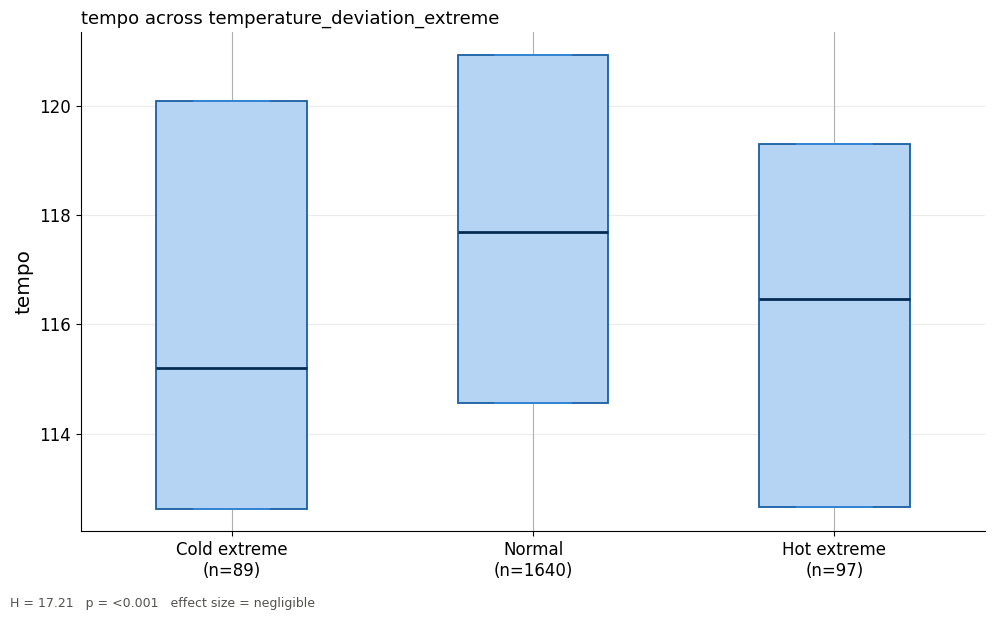

In [30]:
# Kruskal-Wallis box plot: tempo across Cold extreme / Normal / Hot extreme
Image(os.path.join(RESULTS_DIR, "kruskal_extremes_tempo.png"))

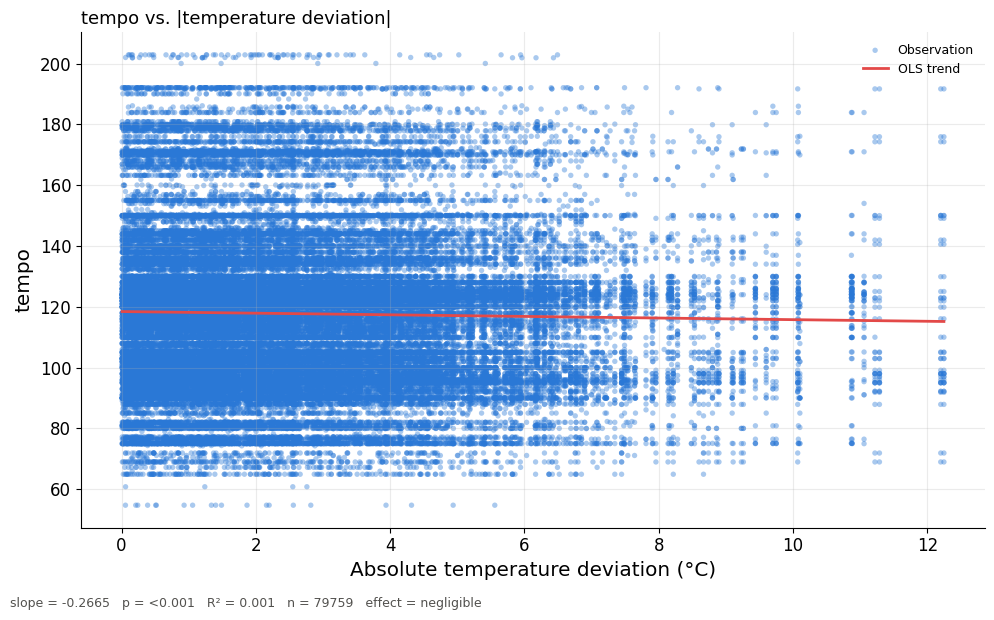

In [31]:
# Magnitude regression scatter plot: tempo vs |temperature_deviation|
Image(os.path.join(RESULTS_DIR, "abs_dev_regression_tempo.png"))

**Interperetation**

H = 17.21 is the 2nd strongest H value across all features in RQ4, though still modest in absolute terms. The magnitude of difference was small (ε² = 0.0094), meaning that temperature extremes accounted for approximately 0.94% of the variation in tempo, and the statistical significance is largely driven by the daily‑aggregated sample size.

Both Cold extreme (p = 0.0028) and Hot extreme (p = 0.0223) days differed significantly from Normal days, while the two extremes did not differ from each other (p = 1.0000). This forms an inverted‑U shape where normal days have the highest tempo (117.68 BPM), and both cold (115.21 BPM) and hot (116.47 BPM) extremes pull tempo downward. The asymmetry is notable: cold days show a larger drop (−2.47 BPM) than hot days (−1.21 BPM).

The median tempos decrease from 117.68 BPM under normal conditions to 115.21 BPM (cold) and 116.47 BPM (hot), but but these differences are below perceptual thresholds, suggesting limited practical relevance.

### 2.2 Danceability

| Test | Result |
|---|---|
| Kruskal-Wallis | H = 10.90, p = 0.0043 **significant** |
| Cold extreme vs. Normal | p <0.0029  **significant** |
| Cold extreme vs. Hot extreme | p = 0.0493  **significant** |
| Normal vs. Hot extreme | p =  1.0000  **not significant** |
| Magnitude regression | slope = −0.0001, p = 0.6870, R² = 0.0000 | 

This pattern suggests that cold extreme days are associated with lower danceability, while normal and hot extreme days show similar levels. The effect size remains negligible

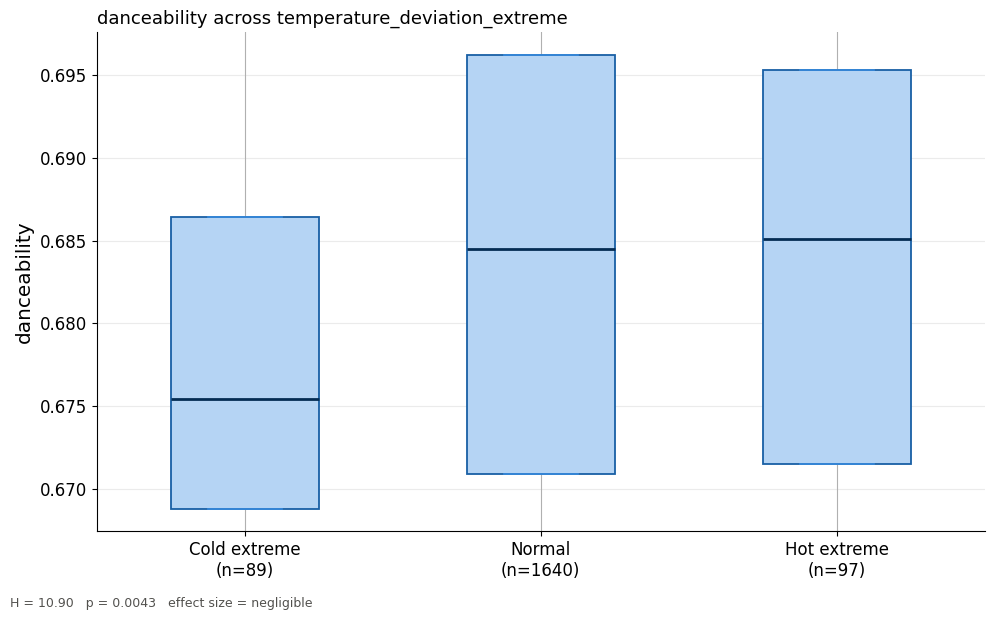

In [32]:
Image(os.path.join(RESULTS_DIR, "kruskal_extremes_danceability.png"))

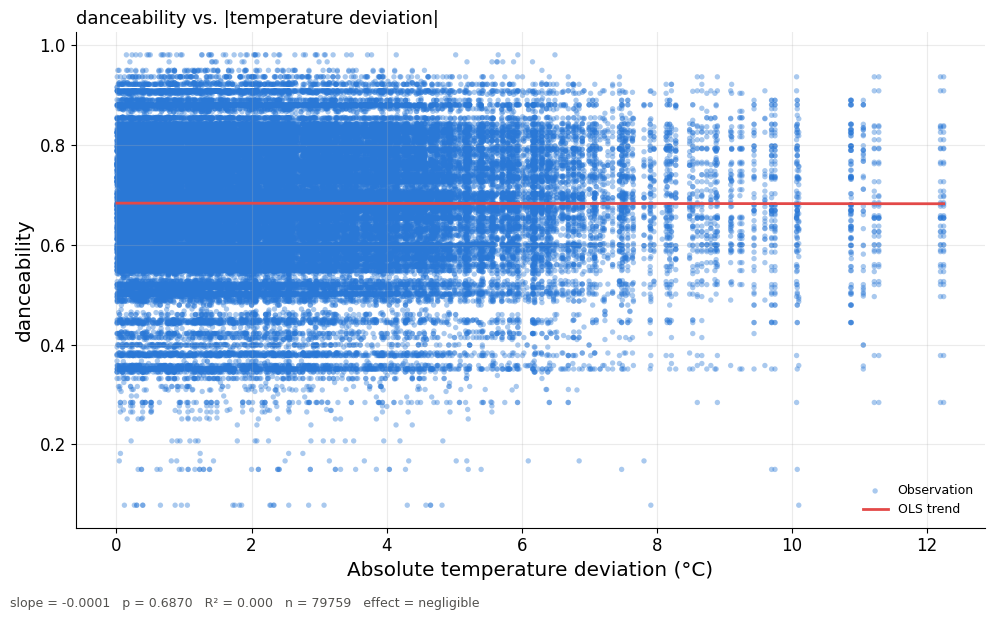

In [33]:
Image(os.path.join(RESULTS_DIR, "abs_dev_regression_danceability.png"))

### 2.3 Valence

| Test | Result |
|---|---|
| Kruskal-Wallis | H = 20.23, p < 0.0001 **significant** |
| Effect size | ε² = 0.0111 **Small** |
| Cold extreme vs. Normal | p =  0.0001 significant |
| Cold extreme vs. Hot extreme | p = 0.0.0096 significant |
| Normal vs. Hot extreme | p = 1.000 not significant |
| Magnitude regression | slope = −0.0013, p = 0.0010, R² = 0.0001 | 

Median valence:- Normal = 0.4956, Cold extreme = 0.4858, Hot extreme =  0.4960 the effect is driven primarily by cold extreme days.
Based on the above table, we can conclude that there is a correlation between cold extreme days and low valence (less positive/more sad), while the valence level is the same for normal and hot extreme days. The effect size is the largest one among all features investigated.

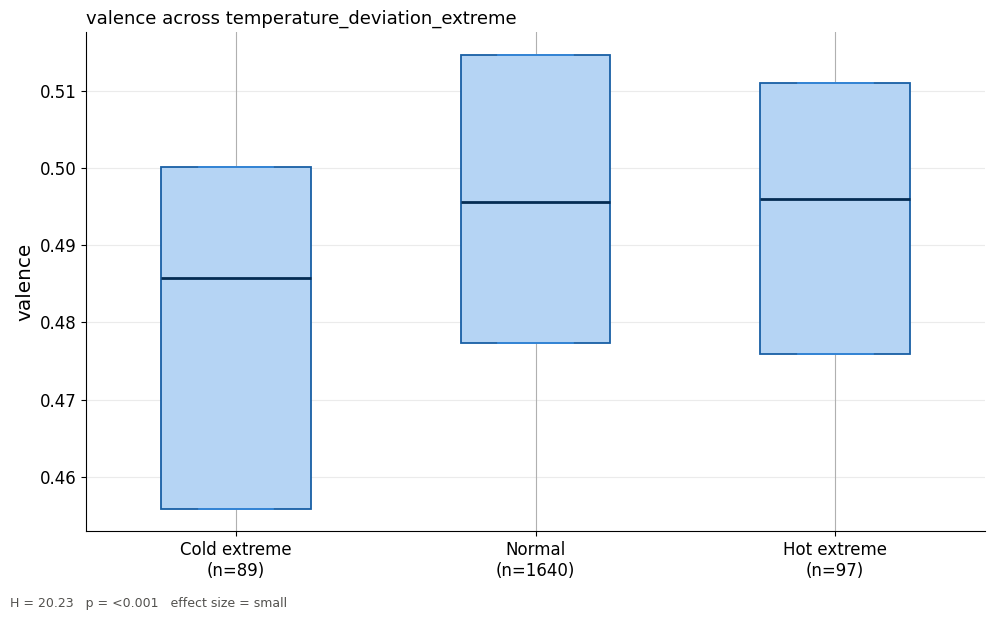

In [34]:
Image(os.path.join(RESULTS_DIR, "kruskal_extremes_valence.png"))

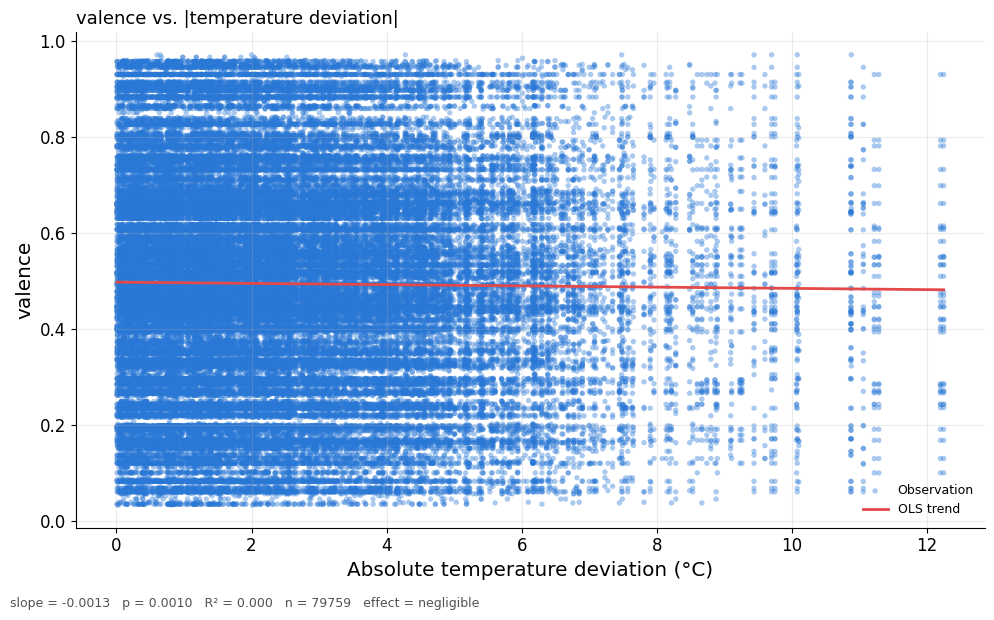

In [35]:
Image(os.path.join(RESULTS_DIR, "abs_dev_regression_valence.png"))

**Interpretation**
An H-value of 20.23 is by far the highest one among all other variables in RQ4, although it remains low in comparison to other coefficients. The value of ε² = 0.0111 proves that variance in temperature extremity explains the variability in valence in about 1.11%, and it is the biggest effect identified in the present study and is considered "small." The p-value (less than 0.0001) proves significance at more than 1% confidence level.

Post-hoc analysis reveals that the effect is asymmetrical because the valence of cold extremes (0.4858) is significantly lower compared to normal valence (0.4956; p < 0.0001), whereas hot extreme valence (0.4960) does not differ from the valence of normal days (p = 1.0000). In addition, the two extreme cases are different from each other (p = 0.0096). It is an asymmetrical correlation when cold extremes reduce valence and not an inverse-U relationship.

Regression results for the magnitude of temperature deviation on valence produced a statistically significant negative slope (−0.0013, p = 0.0010), implying that the greater the deviation of temperature from its mean value (regardless of direction), the slightly lower the level of valence becomes. Nevertheless, almost no variation in valence is explained by the predictor (R² = 0.0001), and hence it is a statistically significant but practically insignificant finding. The negative slope corresponds to the omnibus result; however, regression cannot reflect an important discrepancy foundd using Dunn's multiple comparisons test, since it gives equal weight to cold and hot deviations from the norm. While days with very low temperatures have a median valence of 0.4858 (0.0098 less than normal days at 0.4956), days with high temperaturess have a slightly higher valence of 0.4960 (0.0004 above normal). Therefore, "Normal vs. Hot" is not statistically significant (p = 1.0000), since hot days are indistinguishable from normal oness. The only reason for having a negative regression slope is the pull of cold days' average downward, masking the small increase observed on hot extreme days.

### 2.4 Energy

| Test | Result |
|---|---|
| Kruskal-Wallis | H = 8.49, p = 0.0143 **significant** |
| Effect size | ε² = 0.0047 **negligible** |
| Cold extreme vs. Normal | p =  0.5896  not significant |
| Cold extreme vs. Hot extreme | p =  1.0000 not significant |
| Normal vs. Hot extreme | p = 0.0222 significant |
| Magnitude regression | slope = +0.0003, p = 0.3607, R² = 0.0000 |

Where the medians for Cold extreme: 0.6776, Normal: 0.6731, Hot extreme: 0.6814.
From this pattern, it can be seen that hot extreme days are associated with slightly more energy than normal days; however, no significant difference is seen between cold extreme days and either other group.

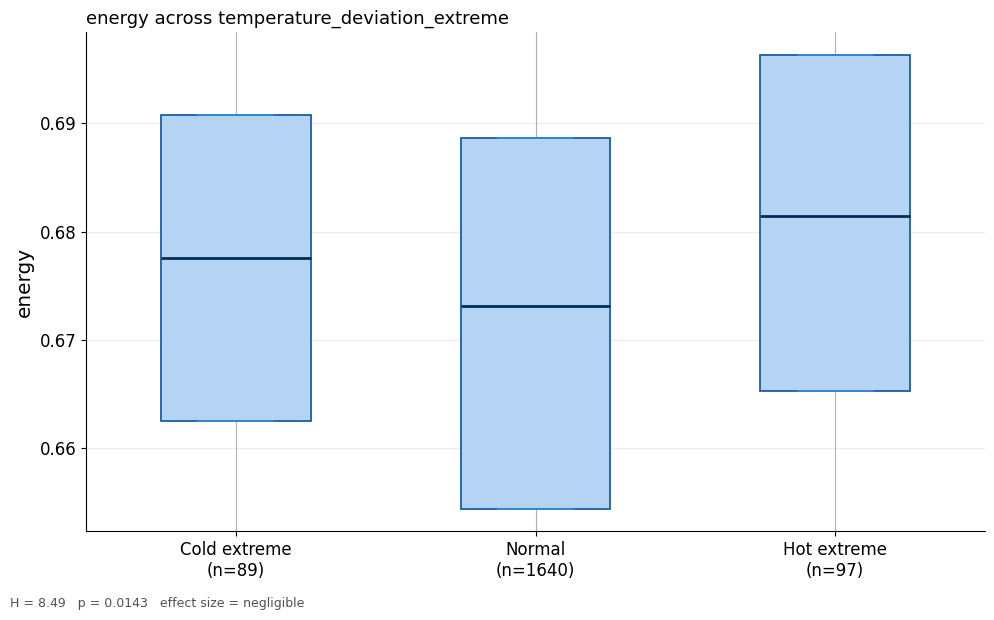

In [36]:
Image(os.path.join(RESULTS_DIR, "kruskal_extremes_energy.png"))

---
### 2.5 **Acousticness**

| Test | Result |
|---|---|
| Kruskal-Wallis | H = 1.01, p = 0.6037 **not significant** |
| Effect size | ε² = 0.0006 **negligible** |
| Post-hoc | Not conducted |
| Magnitude regression | slope = +0.0001, p = 0.7654, R² = 0.0000 |

Acousticness shows no meaningful response to temperature extremes at any level.

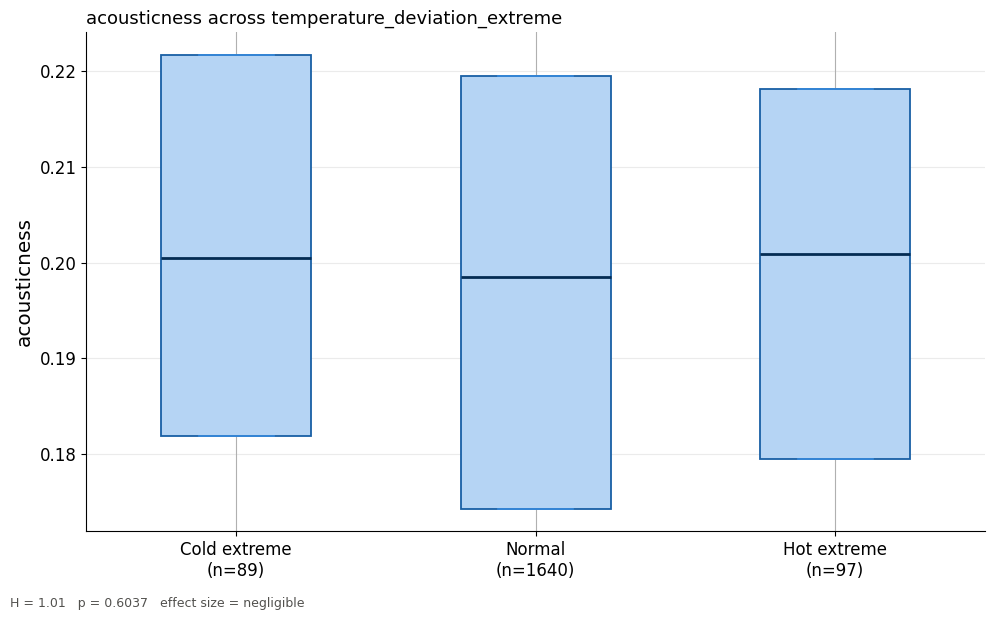

In [37]:
Image(os.path.join(RESULTS_DIR, "kruskal_extremes_acousticness.png"))

Both experiments yield no results, H = 1.01 (p = 0.6037) and no regression was performed for acousticness in this analysis. Temperature deviation does not show any impact on acousticness.

---
In summary, acousticness has a value of zero for both RQ2 and RQ4. Energy is zero for RQ2 but shows significance in RQ4. Tempo is statistically significant for both (though in RQ2 only via Spearman correlation, while the Kruskal‑Wallis test was borderline). Valence is statistically significant for RQ4 but has a value of zero for RQ2. Danceability is statistically significant for both RQ2 and RQ4. Such inconsistencies with the two weather variables suggest that no one audio variable has an established sensitivity to weather in general, and each variable has its own sensitivity to weather.

---
## 3. Caveats
Despite statistical significance for valence, tempo, danceability, and energy, all ε² values are ≤ 0.0111 and the sole R² value (for valence regression) is 0.0001. The strongest effect observed is for valence with ε² = 0.0111 (small), while all others remain negligible. With n = 1,826 independent days, the statistical power is sufficient to detect only very small effects. Extreme temperature deviations explain less than 1% of the variance in any audio feature, except for valence which approaches that threshold. We account for that by calculating Epsilon‑squared for the Kruskal‑Wallis implementation, using Cohen's benchmarks for the effect size, and R² for the Linear Regression (where available).

The hypothesis of U‑shaped relationship partially holds:- Magnitude regression for valence tests whether both hot and cold extremes influence listener behavior. The negative slope (−0.0013, p = 0.0010) indicates that as the magnitude of temperature deviation increases, valence slightly declines. However, the post‑hoc analysis reveals this is driven almost entirely by cold extremes, making the relationship asymmetric rather than a true U‑shape. For tempo, the inverted‑U shape is evident (normal days have the highest tempo), but no regression was performed for this feature.

The cold days produce the difference:- Cold extreme days and normal days are statistically distinct for all three variables (tempo, valence, and danceability). In contrast, hot extreme days are not distinct from normal days for two out of three variables (valence, p = 1.0000; danceability, p = 1.0000); the difference is weakly significant only for tempo (p = 0.0223), but still much less significant compared to cold days vs. normal days difference. The absolute deviation regression for valence (this model is applied to valence only) hides this asymmetry.

| Feature | Cold extreme | Normal | Hot extreme |
|---|---|---|---|
| Tempo (BPM) | 115.21 | 117.68 | 116.47 |
| Valence | 0.4858 | 0.4956 | 0.4960 |

The original scope was Danceability and Tempo:- The significant results for valence are interesting but beyond the RQ, though still an interesting find. Danceability is significant (p = 0.0043), directly showing that temperature extremes impact danceability, with cold days driving the effect. The tempo result, while significant, represents only a ~2.47 BPM drop on cold days (115.21 vs. 117.68 BPM), dwarfed by the natural variation in tempo across songs (IQR ~28 BPM). Energy also shows significance (p = 0.0143), driven by hot days differing from normal, but the effect remains negligible.

---
## 4. Takeaway
Temperature deviations (days that are hotter or colder than would be expected for that season) are correlated with subtle changes in tempo, valence, danceability, and energy, but not acousticness.
For tempo, there is a slight downward trend (about −2.47 BPM) for cold deviations, while hot deviations show a smaller drop (−1.21 BPM), with normal days having the highest tempo. For valence, the effect seems to be almost entirely driven by cold deviations, which are associated with somewhat less positive music (median valence 0.4858 vs. 0.4956 for normal days); hot deviations (0.4960) are essentially like normal days. Danceability also shows a cold‑driven effect, with cold extreme days having lower danceability (0.6754) compared to normal (0.6845) and hot (0.6851) days. Energy shows the opposite pattern, with hot extreme days having slightly higher energy (0.6814) compared to normal (0.6731), while cold extremes (0.6776) do not differ significantly from either.

Danceability, which is the first feature of concern to us, shows correlation with temperature deviation in the group comparison test (H = 10.90, p = 0.0043), although its effect size is small (ε² = 0.0060). Tempo shows very weak correlation (H = 17.21, p = 0.0002, ε² = 0.0094), as well, and it is caused by the cold deviation of temperature. This means that the temperature deviation causes asymmetrical and selective effects on the acoustic profile of the German charts, since cold deviations have stronger effect than hot deviations in most cases. Valence was found to show the greatest correlation effect (ε² = 0.0111), however, it is considered to be a "small" effect.